# Day 25 — Edge Detection & Morphological Operations

**Goal:** implement grayscale conversion, Gaussian smoothing, Sobel/Laplacian/Canny comparisons and all seven morphological operations.

This notebook is self-contained. Select **Run All** in Jupyter, VS Code or Google Colab. Built-in images are reproducible teaching examples. No photo download is required. Change `IMAGE_PATH` below to experiment with a photo.

The outputs already embedded below come from an actual execution of these cells.

In [1]:
# Install packages only if they are missing (works in Colab and Jupyter).
import importlib.util
import subprocess
import sys
packages = {"cv2": "opencv-python-headless>=4.8,<5", "numpy": "numpy>=1.24,<3", "matplotlib": "matplotlib>=3.7,<4"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

from pathlib import Path
import math
import cv2 as cv
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
print("OpenCV:", cv.__version__, "| NumPy:", np.__version__)


OpenCV: 4.14.0 | NumPy: 2.3.5


## Sample images and plotting helpers

The helpers below draw sample inputs, save PNGs and arrange comparisons. The processing code starts in the next section. OpenCV loads color as **BGR**; the plotting helper converts it to RGB for correct colors.

In [2]:
def save_image(path, image):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv.imwrite(str(path), image):
        raise OSError(f"Could not save image: {path}")

def create_samples(folder):
    """Draw reproducible teaching images; no internet download is needed."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(25)
    # BGR color scene: strong boundaries, subtle boundaries and mild noise.
    base = np.tile(np.linspace(30, 85, 800), (500, 1))
    image = np.repeat(base[:, :, None], 3, axis=2)
    image = np.clip(image + rng.normal(0, 5, image.shape), 0, 255).astype(np.uint8)
    cv.rectangle(image, (55, 65), (270, 270), (60, 210, 245), -1)
    cv.circle(image, (420, 170), 100, (215, 150, 65), -1)
    triangle = np.array([[570, 275], [690, 60], [765, 275]], np.int32)
    cv.fillPoly(image, [triangle], (100, 235, 125))
    cv.rectangle(image, (565, 340), (755, 410), (105, 105, 105), -1)
    cv.putText(image, "OpenCV DAY 25", (55, 425), cv.FONT_HERSHEY_SIMPLEX,
               1.5, (245, 245, 245), 3, cv.LINE_AA)
    save_image(folder / "sample_color.png", image)

    # White foreground on black: small white specks, dark holes and a narrow gap.
    binary = np.zeros((360, 640), np.uint8)
    cv.rectangle(binary, (70, 65), (270, 280), 255, -1)
    cv.circle(binary, (430, 180), 95, 255, -1)
    cv.line(binary, (430, 75), (430, 285), 0, 1)
    for center in [(120, 115), (215, 230), (395, 150), (470, 215)]:
        cv.circle(binary, center, 2, 0, -1)
    for center in [(30, 40), (310, 70), (310, 300), (580, 95), (565, 305)]:
        cv.circle(binary, center, 1, 255, -1)
    save_image(folder / "sample_binary.png", binary)

    # Uneven gray background with small bright and dark features for hat filters.
    gray = np.tile(np.linspace(65, 190, 640), (240, 1)).astype(np.uint8)
    cv.circle(gray, (115, 120), 6, 245, -1)
    cv.circle(gray, (520, 120), 6, 15, -1)
    cv.line(gray, (260, 80), (260, 160), 245, 3)
    cv.line(gray, (380, 80), (380, 160), 15, 3)
    save_image(folder / "sample_illumination.png", gray)
    return folder

def display_strength(values):
    """Absolute, per-image normalization for display only, not an edge decision."""
    values = np.abs(values)
    peak = float(values.max())
    if peak == 0:
        return np.zeros(values.shape, np.uint8)
    return np.round(values / peak * 255).astype(np.uint8)

def comparison_grid(items, path, title, columns=3, note=""):
    rows = math.ceil(len(items) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 3.5 * rows),
                             squeeze=False, facecolor="#f7f9fc")
    for ax, (label, image) in zip(axes.flat, items):
        if image.ndim == 3:
            ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(label, fontsize=12, pad=10)
        ax.axis("off")
    for ax in axes.flat[len(items):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=18, fontweight="bold")
    if note:
        fig.text(0.5, 0.012, note, ha="center", fontsize=10)
    # Reserve explicit row gaps so titles never overlap the preceding image.
    margin = 0.65 / (3.5 * rows)
    fig.subplots_adjust(left=0.025, right=0.975, bottom=margin,
                        top=1 - margin - 0.045, wspace=0.10, hspace=0.38)
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=140, facecolor=fig.get_facecolor())
    plt.close(fig)

SAMPLES = create_samples(Path("notebook_assets"))
OUT = Path("notebook_outputs")
OUT.mkdir(exist_ok=True)

def show_grid(items, filename, title, columns=3, note=""):
    path = OUT / filename
    comparison_grid(items, path, title, columns, note)
    display(Image(filename=str(path)))


## 1–2. Grayscale and Gaussian blur

An edge is a rapid spatial change in intensity. Grayscale gives one intensity channel. Gaussian blur suppresses small fluctuations before edge detection; too much blur also removes detail.

Leave `IMAGE_PATH = None` to use the sample. For a photo, set a valid path such as `"my_photo.jpg"`. In Colab, upload the photo first.

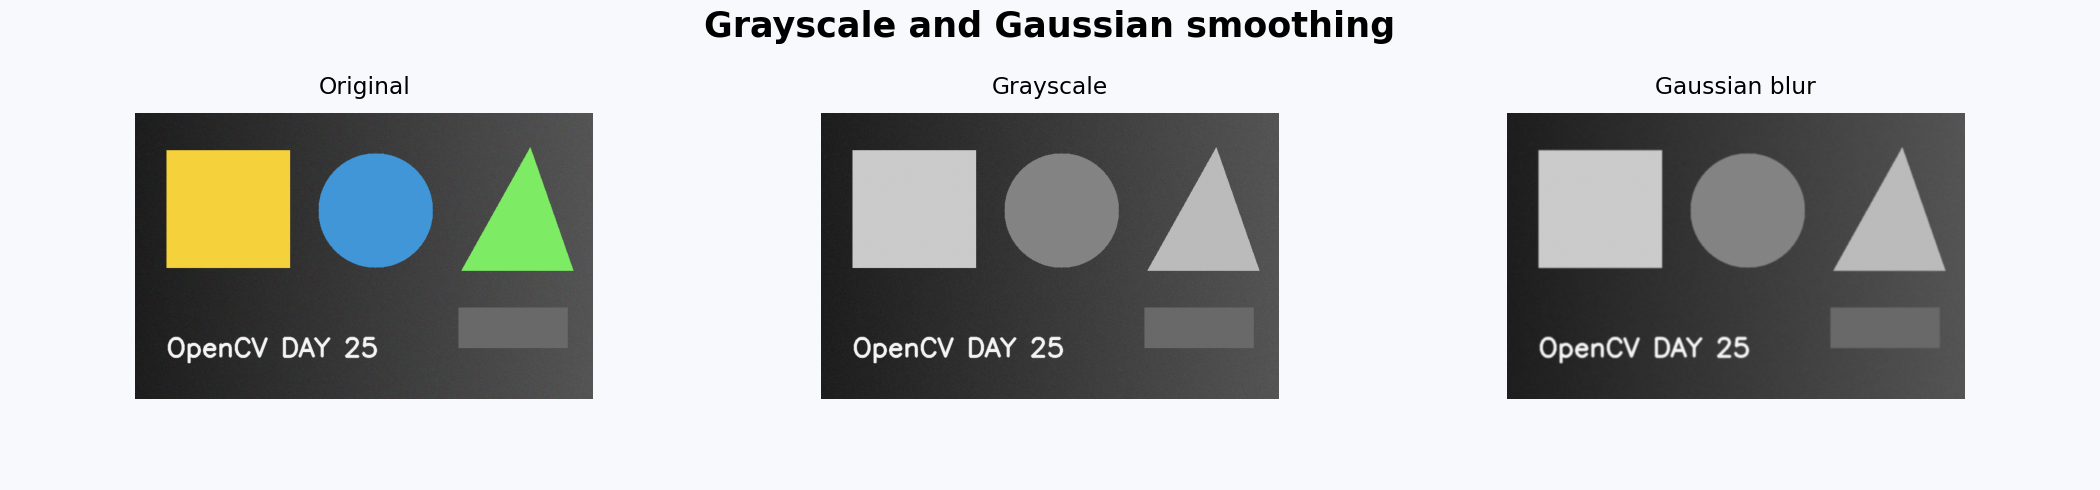

In [3]:
IMAGE_PATH = None
FOREGROUND = "bright"  # Change to "dark" for dark text on light paper.
LOW, HIGH = 50, 150
BLUR_SIZE = 5
KERNEL_SIZE = 5
assert 0 <= LOW < HIGH
assert BLUR_SIZE >= 1 and BLUR_SIZE % 2 == 1
assert KERNEL_SIZE >= 1 and KERNEL_SIZE % 2 == 1
assert FOREGROUND in {"bright", "dark"}

image_path = Path(IMAGE_PATH) if IMAGE_PATH else SAMPLES / "sample_color.png"
image = cv.imread(str(image_path), cv.IMREAD_COLOR)
if image is None:
    raise FileNotFoundError(f"Cannot read {image_path}. Check the path and image format.")
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
blurred = cv.GaussianBlur(gray, (BLUR_SIZE, BLUR_SIZE), 0)
show_grid([("Original", image), ("Grayscale", gray), ("Gaussian blur", blurred)],
          "01_preprocessing.png", "Grayscale and Gaussian smoothing")


## 3a. Sobel

Sobel computes a first derivative. `Gx` measures change across columns and emphasizes vertical boundaries; `Gy` measures change across rows and emphasizes horizontal boundaries. Combine them as $G=\sqrt{G_x^2+G_y^2}$.

Use `CV_64F` to preserve signed derivatives. `display_strength` takes the absolute value and scales to 0–255 for viewing. This scaling is not a decision about which pixels are edges.

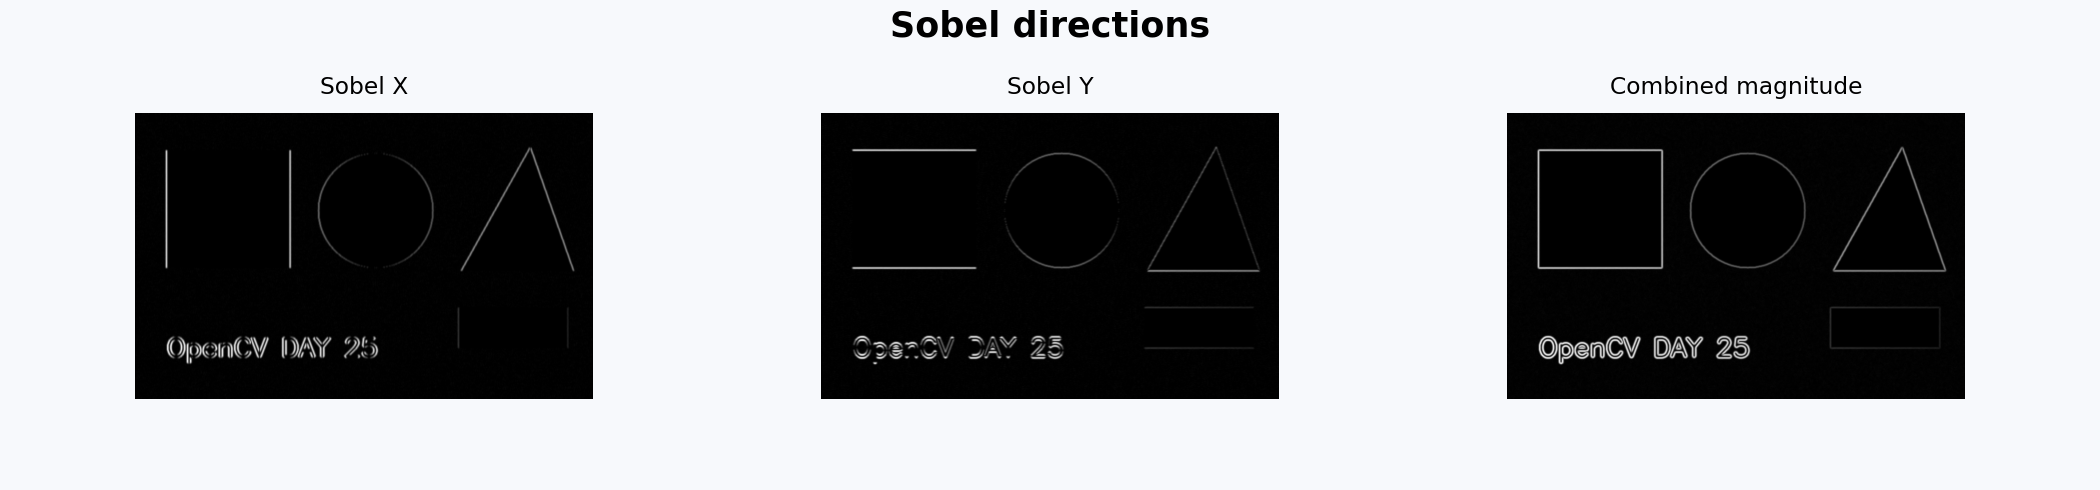

In [4]:
gx = cv.Sobel(blurred, cv.CV_64F, 1, 0, ksize=3)
gy = cv.Sobel(blurred, cv.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv.magnitude(gx, gy)
sobel = display_strength(sobel_magnitude)
show_grid([("Sobel X", display_strength(gx)), ("Sobel Y", display_strength(gy)),
           ("Combined magnitude", sobel)], "02_sobel.png", "Sobel directions")


## 3b–3c. Laplacian and Canny

Laplacian is the sum of second derivatives in X and Y. Here we display its absolute strength; this is not an explicit zero-crossing implementation.

Canny uses gradients, suppression of nonmaximum responses and hysteresis to produce thin binary edges. We apply Gaussian smoothing explicitly before calling it.

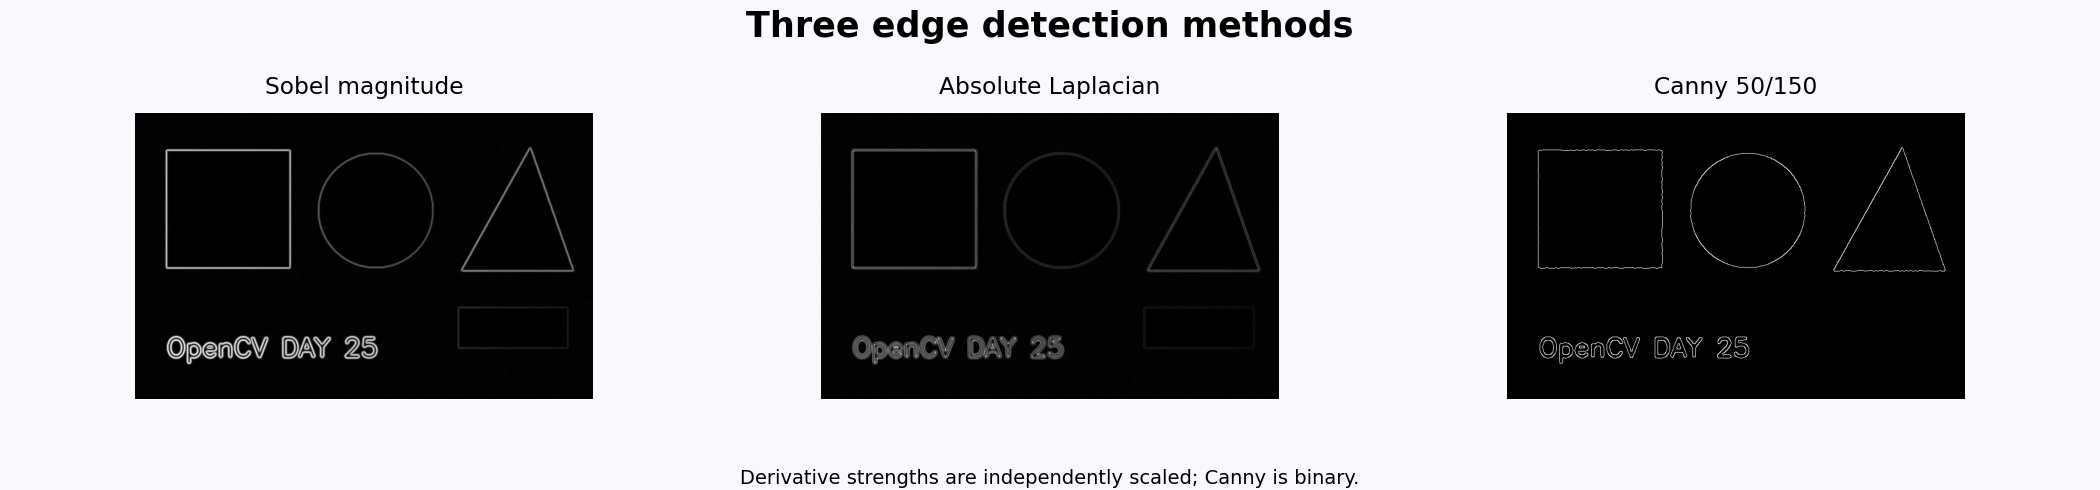

In [5]:
laplacian_raw = cv.Laplacian(blurred, cv.CV_64F, ksize=3)
laplacian = display_strength(laplacian_raw)
canny = cv.Canny(blurred, LOW, HIGH, apertureSize=3, L2gradient=True)
show_grid([("Sobel magnitude", sobel), ("Absolute Laplacian", laplacian),
           (f"Canny {LOW}/{HIGH}", canny)],
          "03_edges.png", "Three edge detection methods",
          note="Derivative strengths are independently scaled; Canny is binary.")


## 4. Compare and tune thresholds

| Method | Output here | Interpretation |
|---|---|---|
| Sobel | Gradient strength | Directional intensity changes |
| Laplacian | Absolute second-derivative response | Changes in the gradient |
| Canny | Binary edge map | Retained thin contours |

A fair input comparison uses the same blurred image. Panel brightness does not measure accuracy, because the derivative images are independently normalized. No labeled ground truth is supplied.

For Canny, the high threshold seeds strong edges. Candidates between the low and high thresholds need connectivity to strong edges. Candidates below the low threshold are rejected. These thresholds apply to gradient response, not original brightness.

The three pairs below are experiments, not universal optimal values. Lower thresholds may recover faint boundaries but also texture. Higher thresholds may discard useful weak contours. Inspect the faint gray rectangle in the sample.

20/60: 4683 edge pixels (not an accuracy score)
50/150: 4162 edge pixels (not an accuracy score)
100/200: 4162 edge pixels (not an accuracy score)


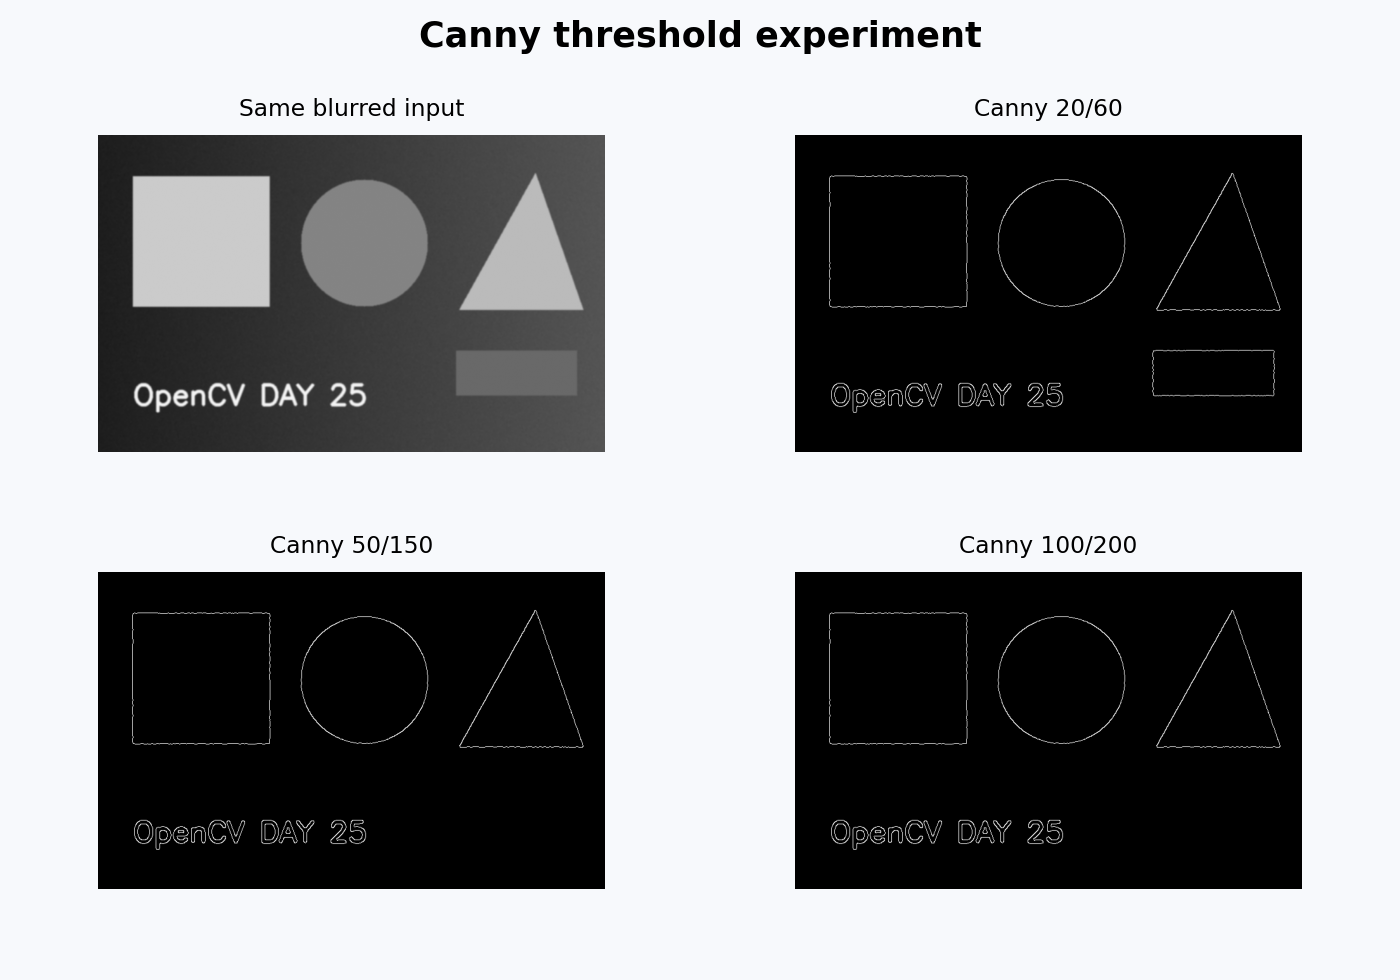

In [6]:
threshold_items = [("Same blurred input", blurred)]
for low, high in [(20, 60), (50, 150), (100, 200)]:
    result = cv.Canny(blurred, low, high, L2gradient=True)
    threshold_items.append((f"Canny {low}/{high}", result))
    print(f"{low}/{high}: {cv.countNonZero(result)} edge pixels (not an accuracy score)")
show_grid(threshold_items, "04_thresholds.png", "Canny threshold experiment", columns=2)


## 5. Apply all morphological operations separately

For this exercise, **white = foreground**. The sample mask includes white specks, black pinholes and a narrow slit. For your own photo we use Otsu thresholding; choose `FOREGROUND = "dark"` when dark writing should become white foreground. A global threshold can struggle with uneven lighting.

| Operation | Definition | Intended local effect |
|---|---|---|
| Erosion | Minimum under kernel | Shrink foreground |
| Dilation | Maximum under kernel | Expand foreground |
| Opening | Erode, then dilate | Remove small white details |
| Closing | Dilate, then erode | Fill small dark holes/gaps |
| Gradient | Dilation minus erosion | Region outlines |
| Top hat | Input minus opening | Small bright details |
| Black hat | Closing minus input | Small dark details |

All seven operations below start from the **same** `binary` image. Kernel scale matters: large kernels can destroy wanted details or merge objects.

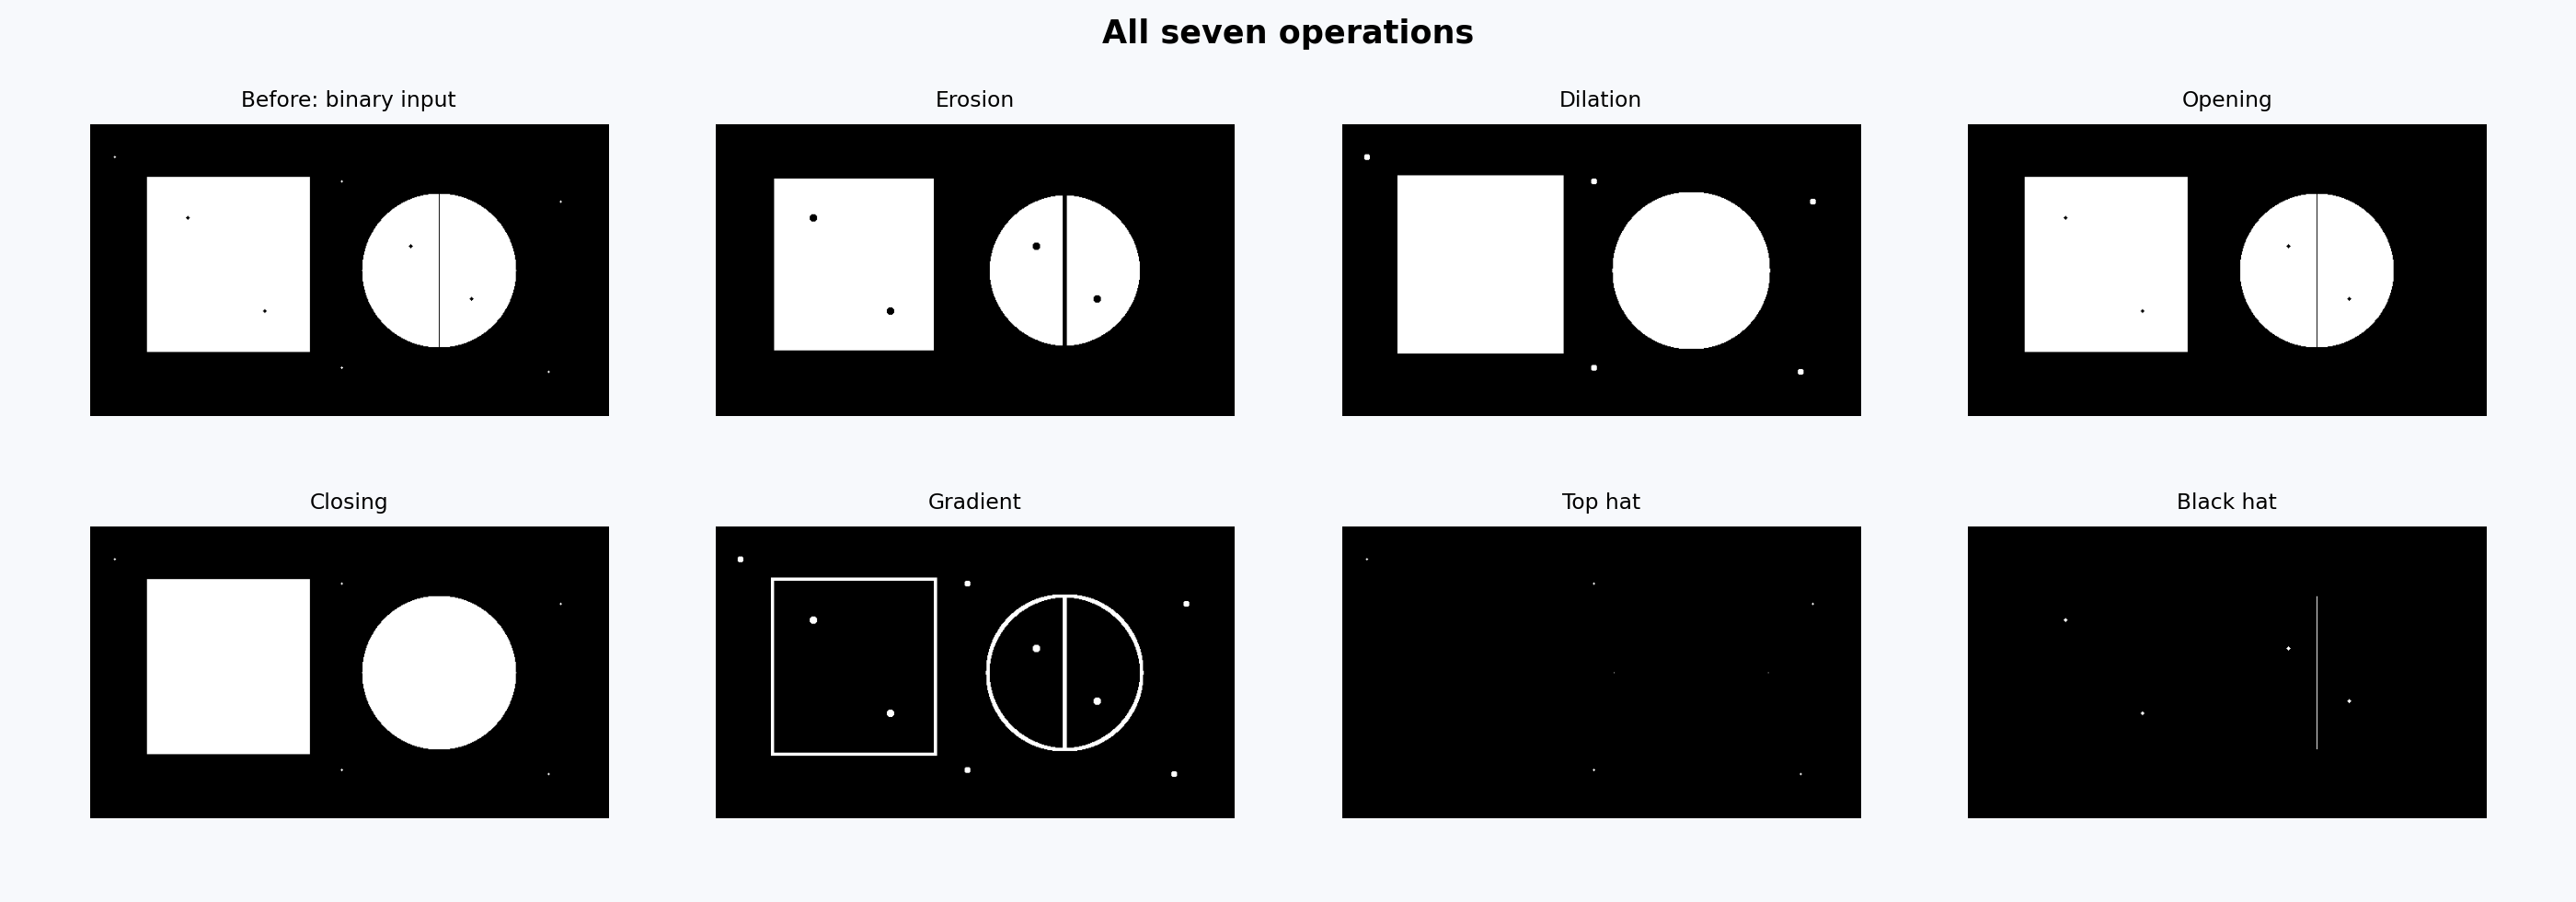

In [7]:
if IMAGE_PATH is None:
    binary = cv.imread(str(SAMPLES / "sample_binary.png"), cv.IMREAD_GRAYSCALE)
else:
    mode = cv.THRESH_BINARY_INV if FOREGROUND == "dark" else cv.THRESH_BINARY
    threshold, binary = cv.threshold(gray, 0, 255, mode | cv.THRESH_OTSU)
    print("Otsu threshold:", threshold)

kernel = cv.getStructuringElement(cv.MORPH_RECT, (KERNEL_SIZE, KERNEL_SIZE))
erosion = cv.erode(binary, kernel, iterations=1)
dilation = cv.dilate(binary, kernel, iterations=1)
opening = cv.morphologyEx(binary, cv.MORPH_OPEN, kernel)
closing = cv.morphologyEx(binary, cv.MORPH_CLOSE, kernel)
gradient = cv.morphologyEx(binary, cv.MORPH_GRADIENT, kernel)
top_hat = cv.morphologyEx(binary, cv.MORPH_TOPHAT, kernel)
black_hat = cv.morphologyEx(binary, cv.MORPH_BLACKHAT, kernel)

morph = {"Erosion": erosion, "Dilation": dilation, "Opening": opening,
         "Closing": closing, "Gradient": gradient, "Top hat": top_hat, "Black hat": black_hat}
show_grid([("Before: binary input", binary), *morph.items()],
          "05_morphology.png", "All seven operations", columns=4)


## 6. Before and after comparison

Inspect the exterior specks, interior pinholes, circle slit and object boundaries. The table below measures white area only. More or fewer pixels does not establish better image quality.

Before: 71543 white pixels
Erosion: 67408 white pixels
Dilation: 75204 white pixels
Opening: 71516 white pixels
Closing: 71784 white pixels
Gradient: 7796 white pixels
Top hat: 27 white pixels
Black hat: 241 white pixels


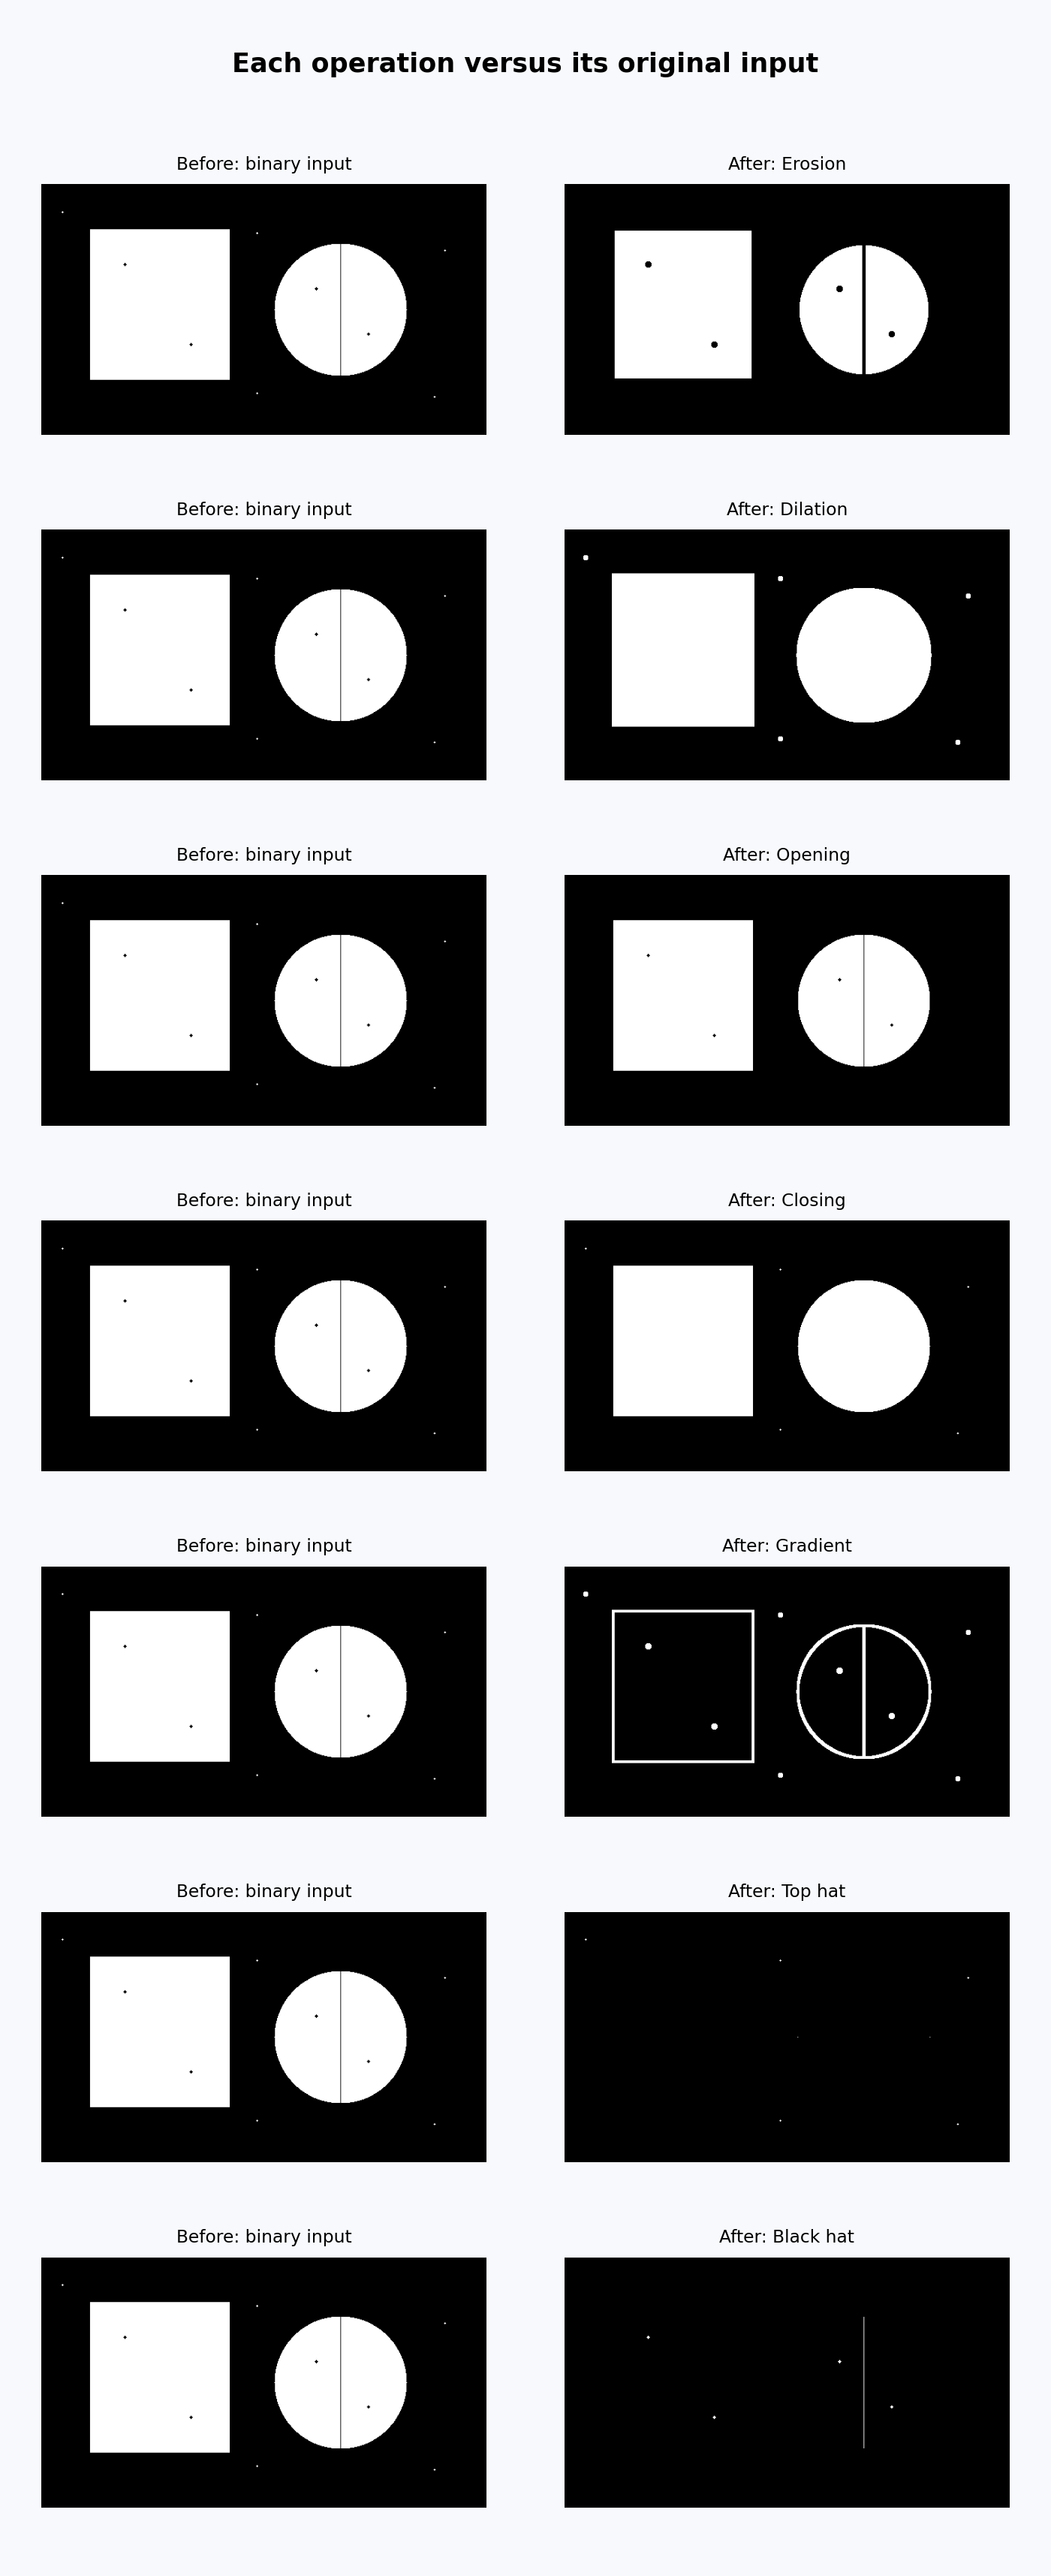

In [8]:
print(f"Before: {cv.countNonZero(binary)} white pixels")
pairs = []
for name, result in morph.items():
    print(f"{name}: {cv.countNonZero(result)} white pixels")
    pairs.extend([("Before: binary input", binary), (f"After: {name}", result)])
show_grid(pairs, "06_before_after.png", "Each operation versus its original input", columns=2)


## Extra: hat filters on a grayscale background

A kernel wider than the small features exposes bright dots/strokes with top hat and dark dots/strokes with black hat. Morphology is also defined for grayscale images.

Saved outputs in: /workspace/scratch/9349416e6847/Day25_Edge_Detection/notebook_outputs


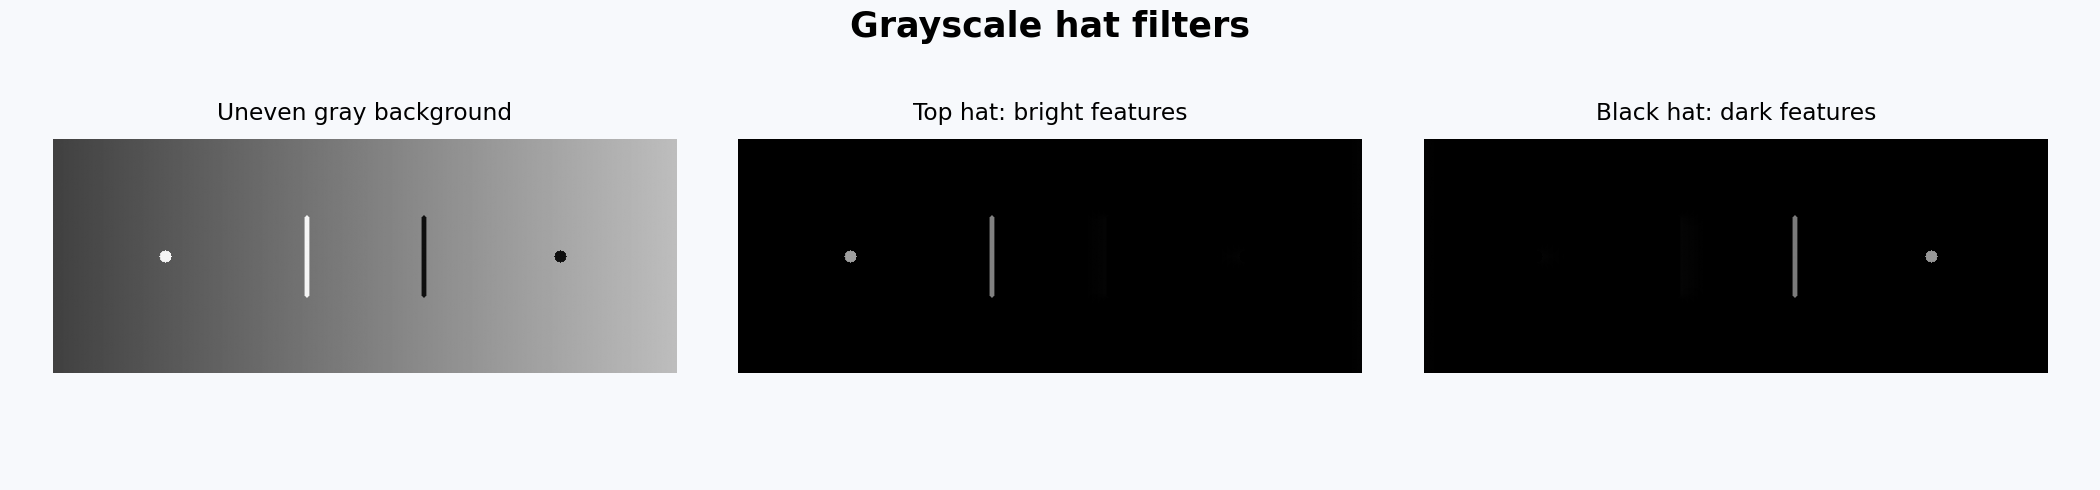

In [9]:
illumination = cv.imread(str(SAMPLES / "sample_illumination.png"), cv.IMREAD_GRAYSCALE)
hat_kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (25, 25))
show_grid([
    ("Uneven gray background", illumination),
    ("Top hat: bright features", cv.morphologyEx(illumination, cv.MORPH_TOPHAT, hat_kernel)),
    ("Black hat: dark features", cv.morphologyEx(illumination, cv.MORPH_BLACKHAT, hat_kernel)),
], "07_grayscale_hats.png", "Grayscale hat filters")

# Save the individual processed images as well as the comparison figures.
individual = {"gray": gray, "blurred": blurred, "sobel": sobel,
              "laplacian": laplacian, "canny": canny, "binary_input": binary, **morph}
for name, result in individual.items():
    save_image(OUT / (name.lower().replace(" ", "_") + ".png"), result)
print("Saved outputs in:", OUT.resolve())


## Observations and applications

On the built-in example, opening removes isolated white dots; closing fills the pinholes and the narrow circle slit. Erosion shrinks the shapes, dilation expands them, and gradient outlines them. Top hat and black hat reveal the small bright and dark features affected by opening and closing.

In the edge demo, Sobel X and Y emphasize different boundary orientations. Canny outputs binary contours; Sobel and Laplacian show graded responses. Threshold changes affect weak details, so select them for the boundaries you need.

Possible applications include document outline extraction, preprocessing writing for OCR, inspecting part boundaries and cleaning a segmentation mask. These techniques support a larger pipeline; they do not recognize objects or read text by themselves.

**Practice:** try morphology kernels 3, 5 and 9, and Gaussian sizes 3 and 7. Inspect details lost or joined. Then repeat on your own image.

**Conclusion:** all six coding requirements are implemented. Thresholds, foreground polarity and kernel size determine which useful details survive.

## Official references

- [OpenCV: Image gradients](https://docs.opencv.org/4.x/d5/d0f/tutorial_py_gradients.html)
- [OpenCV: Canny](https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html)
- [OpenCV: Morphology](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html)
- [OpenCV: Smoothing](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html)
